# Week 7: Gold set, ungrounded baseline, scoring rubric and held-out checks

Runs on the project in `src/` and `eval/`. Results are read from `results/` (regenerate with `python eval/build_gold_set.py` and `python eval/evaluate_week7.py`).

In [1]:
import sys, json, pathlib
import pandas as pd
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import torch  # before faiss on macOS
pd.set_option('display.max_colwidth', 120)

## 1. The gold set (T31)

100 question topics, each in 5 languages:

* **calibration** (40): the week 4-6 questions. The week 6 refusal threshold was set on these.
* **held-out** (60): new this week, never used to tune anything - 50 answerable, 10 unanswerable.

Every answerable topic has a gold page, an evidence phrase copied verbatim from that page (`eval/build_gold_set.py` stops if one is missing) and a short reference answer for hand scoring.

In [2]:
gold = pd.read_csv(ROOT / 'eval/gold_set.csv')
print(gold.groupby(['split', 'answerable']).size().to_string())
gold[gold.split == 'heldout'][['qid', 'question_en', 'evidence', 'reference_answer']].head(10)

split        answerable
calibration  False         10
             True          30
heldout      False         10
             True          50


,qid,question_en,evidence,reference_answer
40,S11,At what age does my child start school?,start reception full-time in september after their fourth birthday,Most children start reception full-time in the September after their fourth birthday.
41,S12,How many children can be in an infant class?,class size is limited to 30,"In reception, year 1 and year 2 classes are limited to 30 children."
42,S13,What happens if my child does not get a place at any school I applied for?,the local council must provide a place at another school,"Yes. If your child is not offered any of the schools you applied for, the council must provide a place at another sc..."
43,S14,How long does a school have to keep its waiting list open?,for at least the first term of each school year,The admission authority must keep a waiting list open for at least the first term of each school year.
44,S15,What happens if I do not pay a school absence fine?,if you do not pay the fine in 28 days,"If you do not pay the fine in 28 days you may be taken to court, where you could be fined up to £2,500, get a commun..."
45,S16,When is my child allowed to miss school?,you have advance permission from the school,"Only if they are too ill to go in, or you have advance permission from the school."
46,S17,Can my child in reception get free school meals?,reception class year 1 year 2,"Yes. Children in reception, year 1 and year 2 at a government-funded school can get free school meals."
47,S18,My child is 9. How far away must the school be to get free school transport?,more than 3 miles away and the child is 8 or over,"For a child aged 8 or over, free transport applies if the nearest suitable school is more than 3 miles away (other c..."
48,S19,How many branded uniform items can a school make me buy?,more than 3 items of branded school uniform,From September 2026 schools should not require more than 3 branded items (4 for secondary and middle schools if one ...
49,S20,How long does the council take to decide on an EHC plan?,within 16 weeks,The local authority must tell you within 16 weeks whether an EHC plan will be made; the final plan is due within 20 ...


In [3]:
pd.read_csv(ROOT / 'eval/heldout_unanswerable.csv').query("lang == 'en'")[['qid', 'question']]

,qid,question
0,U11,How do I apply for a Blue Badge for disabled parking?
5,U12,How do I get a National Insurance number?
10,U13,How much is Child Benefit per week?
15,U14,How do I apply for a student loan for university?
20,U15,How do I report a pothole in my road?
25,U16,My rubbish bin was not collected this week. What should I do?
30,U17,How do I apply for Carer's Allowance?
35,U18,How do I change my name by deed poll?
40,U19,Can I get a free hearing aid on the NHS?
45,U20,How long is statutory maternity leave?


## 2. Does the search stage hold up on new questions?

Same measures as week 5 on the 250 held-out answerable questions: **hit@3** (gold page in the top 3) and **ans@3** (a top-3 passage contains the evidence phrase). Week 5 on the calibration questions: hit@3 1.000, ans@3 0.893.

In [4]:
ret = pd.read_csv(ROOT / 'results/week7_retrieval.csv')
t = ret.groupby('lang')[['hit@3', 'ans@3']].mean().loc[['en', 'pl', 'ro', 'ar', 'ur']]
t.loc['ALL'] = ret[['hit@3', 'ans@3']].mean()
t.round(3).T

lang,en,pl,ro,ar,ur,ALL
hit@3,0.98,0.98,0.98,0.98,0.98,0.980
ans@3,0.98,0.94,0.96,0.96,0.94,0.956


## 3. Refusal rules on held-out questions (T28 re-checked)

The week 6 assistant is used exactly as it was: threshold 0.0052 on the top reranker score, the yes/no check, and NO_ANSWER. Nothing was re-tuned.

W1116 17:30:37.089000 72572 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


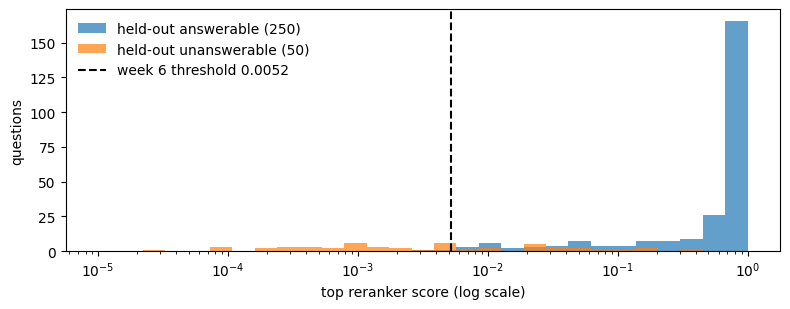

In [5]:
import numpy as np, matplotlib.pyplot as plt
from assistant import THRESHOLD
ans = pd.read_csv(ROOT / 'results/week7_answers.csv')
g = ans[ans.condition == 'grounded']
bins = np.logspace(-5, 0, 30)
plt.figure(figsize=(8, 3.2))
plt.hist(g[g.answerable].top_score, bins=bins, alpha=0.7, label='held-out answerable (250)')
plt.hist(g[~g.answerable].top_score, bins=bins, alpha=0.7, label='held-out unanswerable (50)')
plt.axvline(THRESHOLD, color='k', ls='--', label=f'week 6 threshold {THRESHOLD}')
plt.xscale('log'); plt.xlabel('top reranker score (log scale)'); plt.ylabel('questions'); plt.legend(frameon=False)
plt.tight_layout(); plt.show()

In [6]:
pd.read_csv(ROOT / 'results/week7_refusal.csv')

,answerable,reason,n
0,False,check: not in sources,15
1,False,low relevance,30
2,False,NaN,5
3,True,low relevance,2
4,True,NaN,248


In [7]:
print('answerable questions refused:')
g[g.answerable & g.refused][['qid', 'lang', 'question', 'top_score', 'reason']]

answerable questions refused:


,qid,lang,question,top_score,reason
252,H20,pl,Jaką grzywnę może dostać wynajmujący za nielegalną eksmisję najemcy?,0.003722,low relevance
494,M27,ro,Când ar trebui să fac vaccinul împotriva tusei convulsive în sarcină?,0.004550,low relevance


In [8]:
print('unanswerable questions answered:')
g[~g.answerable & ~g.refused][['qid', 'lang', 'top_score', 'answer']]

unanswerable questions answered:


,qid,lang,top_score,answer
512,U12,pl,0.012538,"Podane wyrywy nie zawierają informacji o sposobie uzyskania numeru National Insurance. Wymieniają tylko, że jest on ..."
514,U12,ro,0.046335,Extractele nu conțin informații despre cum se obține un număr National Insurance. [1]
518,U12,ur,0.023639,آپ اپنا نیشنل انشورنس نمبر (IHS) ویزا یا انیمیشن ایپلیکیشن کے طور پر مکمل کرنے کے بعد حاصل کر سکتے ہیں۔ آپ کو ایک ای...
564,U17,ro,0.202142,"Documentele nu explică cum să aplicați pentru Carer's Allowance. Ele menționează doar că, dacă primiți deja un supli..."
588,U19,ur,0.027225,جی ہاں، آپ کو NHS سے مفت سننے کا آلہ مل سکتا ہے اگر آپ کی عمر، آمدنی، رہائش جگہ، مدد کی کچھ فائدے، حاملہ ہونا یا طبی...


## 4. The ungrounded baseline (T30)

Same model (Qwen3.5-4B), same audience and plain-language rules, same language instruction - but no retrieved passages and no citations. It answers from what the model learned in training.

In [9]:
from generate import baseline_messages
for m in baseline_messages('How quickly must my landlord put my deposit in a protection scheme?', 'en'):
    print(f"--- {m['role']} ---\n{m['content']}\n")

--- system ---
You help people in England understand official guidance on health services, housing and schools.

Rules:
1. Answer the question first. Write in plain language: short sentences, everyday words, no more than 120 words.
2. If you do not know the answer, say so.
3. Do not give medical diagnoses or legal advice about the user's own case; explain what the guidance says.
4. Write the whole answer in English.

--- user ---
How quickly must my landlord put my deposit in a protection scheme?



In [10]:
def compare(qid, lang='en'):
    for r in ans[(ans.qid == qid) & (ans.lang == lang)].itertuples():
        print(f'[{r.condition}] {r.question}\n{r.answer}\n')
    ref = gold[gold.qid == qid].reference_answer.iloc[0]
    print(f'REFERENCE: {ref}\n' + '=' * 80)

for q in ['H12', 'M25', 'H25', 'U11', 'U17']:
    compare(q)

[grounded] How quickly must my landlord put my deposit in a protection scheme?
Your landlord must put your deposit in a protection scheme within 30 days of getting it [1]. If you are in a dispute, the deposit stays protected until the issue is sorted out [2]. If a court orders your landlord to protect the deposit after they failed to do so, they must pay it into a scheme's bank account within 14 days [3].

[ungrounded] How quickly must my landlord put my deposit in a protection scheme?
Your landlord must protect your deposit within 30 days of you moving in. This is a strict legal rule in England. If they miss this deadline, you can get the deposit back plus interest. You can check if they have protected it by using the government's online service. If they haven't protected it in time, you can ask the court to help. Make sure you know which scheme they used, as there are three types available.

REFERENCE: Your landlord or letting agent must put the deposit in a government-approved schem

## 5. Automatic measures, grounded vs ungrounded

These check form, not truth: accuracy and unsupported claims are scored by hand (section 6). Readability: Flesch Reading Ease (higher = easier) and Flesch-Kincaid grade for English answers only; words per sentence for every language.

In [11]:
by = pd.read_csv(ROOT / 'results/week7_by_condition.csv')
by.set_index(['condition', 'lang'])

n_answerable  answerable_refused  cited  cites_answer  \
condition  lang                                                          
grounded   ALL            250               0.008  0.960         0.923   
           en              50               0.000  1.000         0.980   
           pl              50               0.020  0.939         0.898   
           ro              50               0.020  1.000         0.959   
           ar              50               0.000  0.940         0.920   
           ur              50               0.000  0.920         0.860   
ungrounded ALL            250               0.000    NaN           NaN   
           en              50               0.000    NaN           NaN   
           pl              50               0.000    NaN           NaN   
           ro              50               0.000    NaN           NaN   
           ar              50               0.000    NaN           NaN   
           ur              50               0.000    NaN           NaN   

                 lang_ok  words  words_per_sentence  flesch_reading_ease  \
condition  lang                                                            
grounded   ALL       1.0   50.8                17.7                 66.2   
           en        1.0   55.6                17.8                 66.2   
           pl        1.0   40.0                15.0                  NaN   
           ro        1.0   57.4                18.8                  NaN   
           ar        1.0   44.3                16.8                  NaN   
           ur        1.0   56.6                19.9                  NaN   
ungrounded ALL       1.0   78.2                14.2                 72.0   
           en        1.0   80.6                13.2                 71.9   
           pl        1.0   67.1                11.9                  NaN   
           ro        1.0   83.3                15.1                  NaN   
           ar        1.0   71.2                14.2                  NaN   
           ur        1.0   88.7                16.6                  NaN   

                 fk_grade  n_unanswerable  unanswerable_refused  \
condition  lang                                                   
grounded   ALL        8.4              50                   0.9   
           en         8.4              10                   1.0   
           pl         NaN              10                   0.9   
           ro         NaN              10                   0.8   
           ar         NaN              10                   1.0   
           ur         NaN              10                   0.8   
ungrounded ALL        6.4              50                   0.0   
           en         6.4              10                   0.0   
           pl         NaN              10                   0.0   
           ro         NaN              10                   0.0   
           ar         NaN              10                   0.0   
           ur         NaN              10                   0.0   

                 sec_per_answer  
condition  lang                  
grounded   ALL             17.0  
           en              21.3  
           pl              10.8  
           ro              15.7  
           ar              28.6  
           ur               8.9  
ungrounded ALL              8.4  
           en              14.0  
           pl               6.8  
           ro               7.3  
           ar               5.6  
           ur               8.4

## 6. Hand scoring: rubric and blinded sheet (T32)

`docs/scoring-rubric.md` defines four scores: accuracy (correct / partly correct / incorrect / refused), unsupported claim (yes / no), citations (all correct / some wrong / none / n/a) and refusal (correct refusal / answered anyway / n/a). `eval/scoring_sheet.xlsx` has 30 items (15 held-out English topics x 2 conditions), shuffled with the condition hidden, with a tab for each of two raters. Agreement is reported as percentage agreement and Cohen's kappa. The key is in `eval/scoring_key.csv`.

In [12]:
sheet = pd.read_excel(ROOT / 'eval/scoring_sheet.xlsx', sheet_name='rater 1')
sheet[['item', 'question', 'reference_answer', 'answer_to_score']].head(6)

,item,question,reference_answer,answer_to_score
0,1,How much can a landlord be fined for illegally evicting a tenant?,"Local councils can prosecute landlords or give a fine of up to £40,000 for harassment or illegal eviction.","A landlord can be fined up to £40,000 for illegally evicting someone [1]. Local councils can also prosecute landlord..."
1,2,My child is 9. How far away must the school be to get free school transport?,"For a child aged 8 or over, free transport applies if the nearest suitable school is more than 3 miles away (other c...","In England, a 9-year-old child gets free school transport if their home is more than 2 miles from school. This rule ..."
2,3,How much do overseas visitors pay for NHS hospital treatment?,"If you are not ordinarily resident and must pay for NHS hospital treatment, you are charged 150% of the national NHS...","Overseas visitors usually pay the full cost of NHS hospital treatment. This includes tests, operations, and care. Th..."
3,4,Should I drive myself to A&E?,No. Do not drive to A&E. Ask someone to drive you or call 999 for an ambulance.,"You should drive yourself to A&E only if you feel safe and are not too unwell. If you are dizzy, confused, in severe..."
4,5,How much notice do I need to give to leave my rented home?,"You can end an assured periodic tenancy by giving 2 months' notice in writing, and you keep paying rent during the n...","The notice you need depends on your tenancy type. For most private rentals, you must give at least one month's notic..."
5,6,Can I get a GP appointment in the evening or at the weekend?,Yes. You can see a healthcare professional on weekday evenings 6.30pm to 8pm and on Saturdays 9am to 5pm.,"Yes, you can get a GP appointment in the evening or at the weekend. You can book these by calling your GP surgery or..."


## 7. Findings (full local run, 16 Nov 2026)

1. **The search stage holds up on new questions.** On the 250 held-out answerable questions, hit@3 was 0.980 and
   ans@3 0.956 (week 5, calibration questions: 1.000 and 0.893). The held-out questions were written by the author
   after reading the pages, so they may be easier than real users' questions; this is a limitation, not a gain.
2. **The week 6 refusal rules mostly carry over without re-tuning.**
   * 2 of 250 answerable questions were wrongly refused (H20 Polish, M27 Romanian). In both, the answer passage was
     retrieved, but the top score (0.0037 and 0.0046) fell just under the threshold of 0.0052. In week 6, none of 150
     were refused.
   * 45 of 50 unanswerable questions were refused (week 6: 43 of 50): 30 by the threshold, 15 by the yes/no check.
   * Of the 5 that were answered, 3 are prose refusals ("the extracts do not contain…"). The other 2, both Urdu, are
     real errors:
     * U12 turns a passage about the IHS reference number into an answer about getting a National Insurance number;
     * U19 applies a general "help with NHS costs" passage to hearing aids.
3. **The ungrounded baseline never says it does not know.** It answered all 300 questions, including all 50
   unanswerable ones, although its prompt allows "say so". Compared with the reference answers from the official pages:
   * **H25:** it invents a "Child Tax Free Amount" of £210.50 a month (the page says £303.94).
   * **S11:** it says children cannot start school before their fifth birthday (the page: reception starts in the
     September after the fourth birthday).
   * **M25:** it adds a "visitor surcharge" of about £200.
   These are examples only; rates come from the hand scoring.
4. **Grounded answers cite their sources.**
   * 96.0% have valid citations.
   * 92.3% cite the passage that holds the answer phrase (week 6: 83.3%).
   * Urdu is the weakest language (0.920 and 0.860).
   * All answers in both conditions are in the question's language.
5. **The baseline reads more easily but has nothing behind it.** In English, the grounded answers score Flesch Reading
   Ease 66.2 and FK grade 8.4 (17.8 words per sentence). The ungrounded answers score 71.9 and grade 6.4 (13.2 words
   per sentence). Grounded answers keep the official wording, which has longer sentences.
6. **Hand scoring is prepared, not done.** `eval/scoring_sheet.xlsx` holds 30 blinded items for two raters. Accuracy,
   hallucination and citation-correctness figures will come from those scores, not from this notebook.
